# 微引力导星仪单星满阱饱和分析

本 notebook 复用凌星导星仪报告的分析结构，对微引力导星仪做 31 x 31 单星 stamp 的满阱饱和测试。参数从 `/home/liyang/ET7/Photsim7-data/et_inputs_microlens_guider.xlsx` 读取，并按本次测试要求覆盖：曝光 `0.25 s`、满阱 `1800 e`、bias `135 ADU`、gain `0.45 e/ADU`。PSF 使用 `/home/liyang/ET7/Photsim7-data/psf/et/microlens/RebinnedPSF_LE_BEST_GD1_Field1_multiband_Defocus0/sim_psf_images.pkl`。

同时计算两种情况：不乘额外效率因子，以及单星和天光背景同时乘 `QE = 0.55`、`throughput = 0.52`，即总光子效率因子 `0.286`。

In [ ]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REPO_DIR = Path('/home/liyang/ET7/ET-fsgsim')
SCRIPT_PATH = REPO_DIR / 'scripts' / 'guide_stamp_saturation_sweep.py'
PYTHON = Path('/home/liyang/anaconda3/envs/py311/bin/python')

CONFIG_XLSX = Path('/home/liyang/ET7/Photsim7-data/et_inputs_microlens_guider.xlsx')
PSF_BUNDLE_FILE = Path('/home/liyang/ET7/Photsim7-data/psf/et/microlens/RebinnedPSF_LE_BEST_GD1_Field1_multiband_Defocus0/sim_psf_images.pkl')
BASE_DIR = Path('/home/liyang/ET7/Results/FSG_guide_sims/microlens_single_star_saturation_sweep')
EFF_DIR = Path('/home/liyang/ET7/Results/FSG_guide_sims/microlens_single_star_saturation_sweep_qe0p55_throughput0p52')
ASSET_DIR = Path('/home/liyang/ET7/ET-fsgsim/notebooks/microlens_guide_star_saturation_report_files')
ASSET_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    'figure.dpi': 120,
    'savefig.dpi': 220,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

print('PSF path:', PSF_BUNDLE_FILE)
print('PSF exists:', PSF_BUNDLE_FILE.is_file())
print('Config xlsx:', CONFIG_XLSX)
print('Config exists:', CONFIG_XLSX.is_file())

PSF path: /home/liyang/ET7/Photsim7-data/psf/et/microlens/RebinnedPSF_LE_BEST_GD1_Field1_multiband_Defocus0/sim_psf_images.pkl
PSF exists: True
Config xlsx: /home/liyang/ET7/Photsim7-data/et_inputs_microlens_guider.xlsx
Config exists: True


In [2]:
def load_case(label, result_dir):
    result_dir = Path(result_dir)
    summary = pd.read_csv(result_dir / 'saturation_summary.csv')
    numeric_columns = [
        'mag', 'photon_efficiency', 'base_photon_rate_e_per_s', 'base_photon_count_e_0p25s',
        'photon_rate_e_per_s', 'photon_count_e_0p25s', 'expected_peak_star_e',
        'expected_total_star_e', 'max_charge_e_sample0', 'max_charge_e_median',
        'max_charge_e_p95', 'max_charge_e_max', 'saturation_fraction', 'max_adc_adu_sample0',
    ]
    for column in numeric_columns:
        if column in summary.columns:
            summary[column] = pd.to_numeric(summary[column])
    if 'saturated_frames' in summary.columns:
        summary['saturated_frames'] = pd.to_numeric(summary['saturated_frames']).astype(int)
    if 'max_saturated_pixels_in_frame' in summary.columns:
        summary['max_saturated_pixels_in_frame'] = pd.to_numeric(summary['max_saturated_pixels_in_frame']).astype(int)
    with (result_dir / 'saturation_metadata.json').open('r', encoding='utf-8') as handle:
        metadata = json.load(handle)
    stamps = np.load(result_dir / 'single_star_stamps_31x31.npz')
    summary['case'] = label
    return {'label': label, 'dir': result_dir, 'summary': summary, 'metadata': metadata, 'stamps': stamps}

cases = {
    'baseline': load_case('no extra efficiency factor', BASE_DIR),
    'efficiency': load_case('QE=0.55, throughput=0.52', EFF_DIR),
}

combined = pd.concat([case['summary'] for case in cases.values()], ignore_index=True)
base_meta = cases['baseline']['metadata']
eff_meta = cases['efficiency']['metadata']

print('Baseline first saturated mag:', base_meta['first_mag_with_any_saturated_realization'])
print('Baseline all saturated from mag:', base_meta['first_mag_with_all_realizations_saturated'])
print('QE=0.55, throughput=0.52 first saturated mag:', eff_meta['first_mag_with_any_saturated_realization'])
print('QE=0.55, throughput=0.52 all saturated from mag:', eff_meta['first_mag_with_all_realizations_saturated'])

Baseline first saturated mag: 10.5
Baseline all saturated from mag: 10.0
QE=0.55, throughput=0.52 first saturated mag: 9.0
QE=0.55, throughput=0.52 all saturated from mag: 9.0


## 星等到电子数的换算

Photsim7 中 ET 星等到单镜电子流量使用：

$$
F_\star(m) = 1.11 \times 10^4 \times 10^{-0.4(m - 12.5)}\quad \mathrm{e\ s^{-1}}
$$

单次曝光的单星总电子数为：

$$
N_\star(m) = F_\star(m)\ t_\mathrm{exp}\ \eta
$$

其中本分析固定 $t_\mathrm{exp}=0.25\ \mathrm{s}$。baseline 使用 $\eta=1$；效率分支使用 $\eta=0.55\times0.52=0.286$，并将同一个 $\eta$ 同时乘到单星电子数和天光背景电子数。暗电流和散射光按探测器本底项处理，不乘这个光子效率分支因子。

微引力导星仪 xlsx 中 `Pixel Width = 6.5 um`，本次指定焦距为 `5160 mm`，对应像元角尺度约为：

$$
206265 \times \frac{6.5\times10^{-3}\ \mathrm{mm}}{5160\ \mathrm{mm}} = 0.2598\ \mathrm{arcsec\ pix^{-1}}
$$

In [3]:
xlsx_params = base_meta.get('xlsx_parameters_used_for_microlens', {})
parameter_rows = [
    ('config xlsx', str(CONFIG_XLSX)),
    ('PSF file', str(PSF_BUNDLE_FILE)),
    ('PSF field id', base_meta['psf_field_id']),
    ('stamp size', f"{base_meta['stamp_size_pix']} x {base_meta['stamp_size_pix']} pix"),
    ('subpixels per pixel dim', base_meta['subpixels_per_pixel_dim']),
    ('focal length', f"{base_meta['focal_length_mm']} mm"),
    ('pixel width from xlsx', f"{xlsx_params.get('Pixel Width')} um"),
    ('pixel scale from xlsx', f"{base_meta['pixel_scale_arcsec_per_pix']:.4f} arcsec/pix"),
    ('exposure used', f"{base_meta['exposure_s']} s"),
    ('xlsx exposure value', f"{xlsx_params.get('Exposure Duration')} s"),
    ('background mode', base_meta['background_mode']),
    ('background flux before efficiency', f"{base_meta['background_flux_e_per_s_per_pix_before_efficiency']:.6f} e/s/pix"),
    ('dark current', f"{base_meta['dark_current_e_per_s_per_pix']:.3f} e/s/pix"),
    ('scattered light', f"{base_meta['scattered_light_e_per_s_per_pix']:.3f} e/s/pix"),
    ('readout noise', f"{base_meta['readout_noise_e_per_pix']:.3f} e/pix"),
    ('full well', f"{base_meta['full_well_electrons']:.0f} e"),
    ('bias', f"{base_meta['bias_level_adu']:.0f} ADU"),
    ('gain', f"{base_meta['gain_electrons_per_adu']:.2f} e/ADU"),
    ('ADC bit depth', base_meta['adc_bit_depth']),
    ('realizations per magnitude', base_meta['n_realizations_per_mag']),
    ('random seed', base_meta['seed']),
]
parameter_table = pd.DataFrame(parameter_rows, columns=['parameter', 'value'])
parameter_table.to_csv(ASSET_DIR / 'microlens_effective_parameters.csv', index=False)
display(parameter_table)

,parameter,value
0,config xlsx,/home/liyang/ET7/Photsim7-data/et_inputs_micro...
1,PSF file,/home/liyang/ET7/Photsim7-data/psf/et/microlen...
2,PSF field id,0
3,stamp size,31 x 31 pix
4,subpixels per pixel dim,1
5,focal length,5160.0 mm
6,pixel width from xlsx,6.5 um
7,pixel scale from xlsx,0.2598 arcsec/pix
8,exposure used,0.25 s
9,xlsx exposure value,10 s


In [4]:
photon_table = combined[[
    'case', 'mag', 'base_photon_rate_e_per_s', 'base_photon_count_e_0p25s',
    'photon_efficiency', 'photon_rate_e_per_s', 'photon_count_e_0p25s',
    'expected_total_star_e', 'expected_peak_star_e',
]].copy()
photon_table = photon_table.rename(columns={
    'base_photon_rate_e_per_s': 'base flux e/s',
    'base_photon_count_e_0p25s': 'base total e / 0.25 s',
    'photon_efficiency': 'efficiency eta',
    'photon_rate_e_per_s': 'effective flux e/s',
    'photon_count_e_0p25s': 'effective total e / 0.25 s',
    'expected_total_star_e': 'PSF stamp total e',
    'expected_peak_star_e': 'expected peak pixel e',
})
photon_table.to_csv(ASSET_DIR / 'microlens_magnitude_flux_table.csv', index=False)
display(photon_table.style.format({
    'mag': '{:.1f}',
    'base flux e/s': '{:.3f}',
    'base total e / 0.25 s': '{:.3f}',
    'efficiency eta': '{:.2f}',
    'effective flux e/s': '{:.3f}',
    'effective total e / 0.25 s': '{:.3f}',
    'PSF stamp total e': '{:.3f}',
    'expected peak pixel e': '{:.3f}',
}))

,case,mag,base flux e/s,base total e / 0.25 s,efficiency eta,effective flux e/s,effective total e / 0.25 s,PSF stamp total e,expected peak pixel e
0,no extra efficiency factor,14.0,2788.194,697.048,1.00,2788.194,697.048,669.963,70.398
1,no extra efficiency factor,13.5,4418.990,1104.747,1.00,4418.990,1104.747,1061.820,111.573
2,no extra efficiency factor,13.0,7003.627,1750.907,1.00,7003.627,1750.907,1682.871,176.831
3,no extra efficiency factor,12.5,11100.000,2775.000,1.00,11100.000,2775.000,2667.171,280.259
4,no extra efficiency factor,12.0,17592.314,4398.079,1.00,17592.314,4398.079,4227.182,444.180
5,no extra efficiency factor,11.5,27881.939,6970.485,1.00,27881.939,6970.485,6699.632,703.979
6,no extra efficiency factor,11.0,44189.896,11047.474,1.00,44189.896,11047.474,10618.201,1115.731
7,no extra efficiency factor,10.5,70036.265,17509.066,1.00,70036.265,17509.066,16828.714,1768.314
8,no extra efficiency factor,10.0,111000.000,27750.000,1.00,111000.000,27750.000,26671.715,2802.589
9,no extra efficiency factor,9.5,175923.144,43980.786,1.00,175923.144,43980.786,42271.818,4441.804


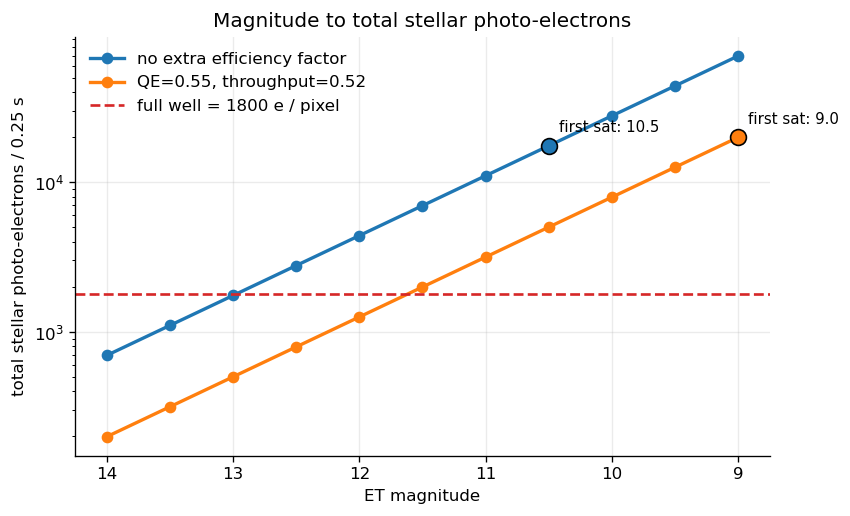

In [5]:
fig, ax = plt.subplots(figsize=(7.2, 4.4))
for key, case in cases.items():
    df = case['summary'].sort_values('mag')
    ax.plot(df['mag'], df['photon_count_e_0p25s'], marker='o', linewidth=2, label=case['label'])
ax.axhline(base_meta['full_well_electrons'], color='tab:red', linestyle='--', linewidth=1.6, label='full well = 1800 e / pixel')
for key, case in cases.items():
    first_mag = case['metadata']['first_mag_with_any_saturated_realization']
    if first_mag is not None:
        first_mag = float(first_mag)
        y_val = float(case['summary'].loc[np.isclose(case['summary']['mag'], first_mag), 'photon_count_e_0p25s'].iloc[0])
        ax.scatter([first_mag], [y_val], s=90, edgecolor='black', linewidth=1.0, zorder=4)
        ax.annotate(f"first sat: {first_mag:.1f}", (first_mag, y_val), xytext=(6, 8), textcoords='offset points', fontsize=9)
ax.set_yscale('log')
ax.set_xlabel('ET magnitude')
ax.set_ylabel('total stellar photo-electrons / 0.25 s')
ax.set_title('Magnitude to total stellar photo-electrons')
ax.invert_xaxis()
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(ASSET_DIR / 'microlens_total_photoelectrons_vs_mag.png')
plt.show()

In [6]:
saturation_table = combined[[
    'case', 'mag', 'expected_peak_star_e', 'max_charge_e_median', 'max_charge_e_p95',
    'max_charge_e_max', 'saturated_frames', 'saturation_fraction', 'max_saturated_pixels_in_frame',
]].copy()
saturation_table = saturation_table.rename(columns={
    'expected_peak_star_e': 'expected peak e',
    'max_charge_e_median': 'median max charge e',
    'max_charge_e_p95': 'p95 max charge e',
    'max_charge_e_max': 'max charge e',
    'saturated_frames': 'saturated frames / 500',
    'saturation_fraction': 'saturation fraction',
    'max_saturated_pixels_in_frame': 'max saturated pixels / frame',
})
saturation_table.to_csv(ASSET_DIR / 'microlens_saturation_summary_table.csv', index=False)
display(saturation_table.style.format({
    'mag': '{:.1f}',
    'expected peak e': '{:.2f}',
    'median max charge e': '{:.2f}',
    'p95 max charge e': '{:.2f}',
    'max charge e': '{:.2f}',
    'saturation fraction': '{:.3f}',
}))

,case,mag,expected peak e,median max charge e,p95 max charge e,max charge e,saturated frames / 500,saturation fraction,max saturated pixels / frame
0,no extra efficiency factor,14.0,70.40,75.00,88.00,99.00,0,0.000,0
1,no extra efficiency factor,13.5,111.57,117.00,134.00,144.00,0,0.000,0
2,no extra efficiency factor,13.0,176.83,185.00,207.00,222.00,0,0.000,0
3,no extra efficiency factor,12.5,280.26,289.00,314.00,339.00,0,0.000,0
4,no extra efficiency factor,12.0,444.18,456.00,484.00,511.00,0,0.000,0
5,no extra efficiency factor,11.5,703.98,717.00,761.00,791.00,0,0.000,0
6,no extra efficiency factor,11.0,1115.73,1134.00,1183.05,1226.00,0,0.000,0
7,no extra efficiency factor,10.5,1768.31,1792.00,1844.10,1922.00,195,0.390,2
8,no extra efficiency factor,10.0,2802.59,2828.00,2901.10,2987.00,500,1.000,3
9,no extra efficiency factor,9.5,4441.80,4473.00,4570.00,4676.00,500,1.000,5


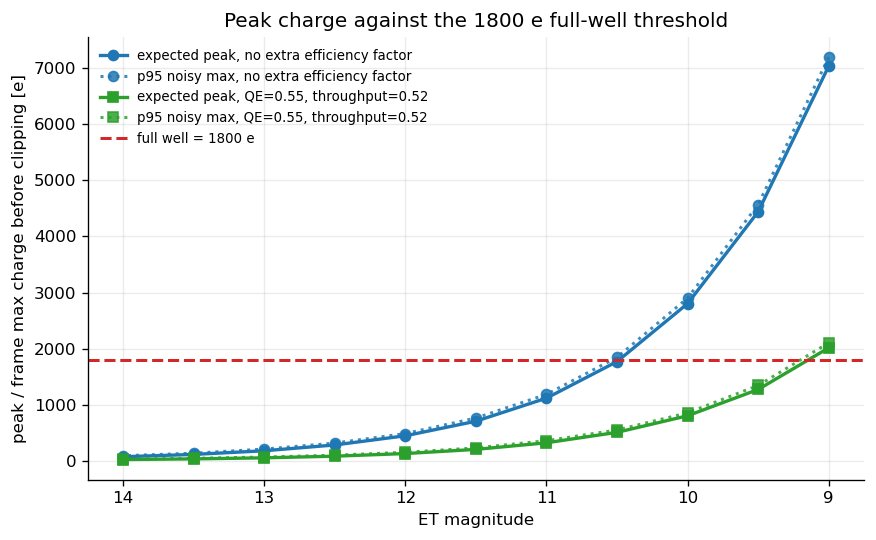

In [7]:
fig, ax = plt.subplots(figsize=(7.4, 4.6))
styles = {
    'baseline': {'color': 'tab:blue', 'marker': 'o'},
    'efficiency': {'color': 'tab:green', 'marker': 's'},
}
for key, case in cases.items():
    df = case['summary'].sort_values('mag')
    ax.plot(df['mag'], df['expected_peak_star_e'], marker=styles[key]['marker'], color=styles[key]['color'], linewidth=2, label=f"expected peak, {case['label']}")
    ax.plot(df['mag'], df['max_charge_e_p95'], marker=styles[key]['marker'], color=styles[key]['color'], linestyle=':', linewidth=1.8, alpha=0.85, label=f"p95 noisy max, {case['label']}")
ax.axhline(base_meta['full_well_electrons'], color='tab:red', linestyle='--', linewidth=1.8, label='full well = 1800 e')
ax.set_xlabel('ET magnitude')
ax.set_ylabel('peak / frame max charge before clipping [e]')
ax.set_title('Peak charge against the 1800 e full-well threshold')
ax.invert_xaxis()
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(ASSET_DIR / 'microlens_peak_charge_full_well.png')
plt.show()

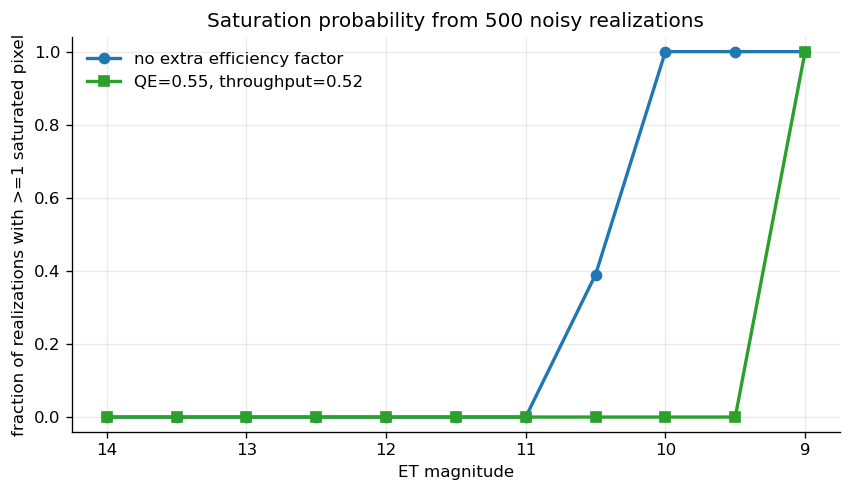

In [8]:
fig, ax = plt.subplots(figsize=(7.2, 4.2))
for key, case in cases.items():
    df = case['summary'].sort_values('mag')
    ax.plot(df['mag'], df['saturation_fraction'], marker=styles[key]['marker'], color=styles[key]['color'], linewidth=2, label=case['label'])
ax.set_xlabel('ET magnitude')
ax.set_ylabel('fraction of realizations with >=1 saturated pixel')
ax.set_title('Saturation probability from 500 noisy realizations')
ax.set_ylim(-0.04, 1.04)
ax.invert_xaxis()
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(ASSET_DIR / 'microlens_saturation_probability.png')
plt.show()

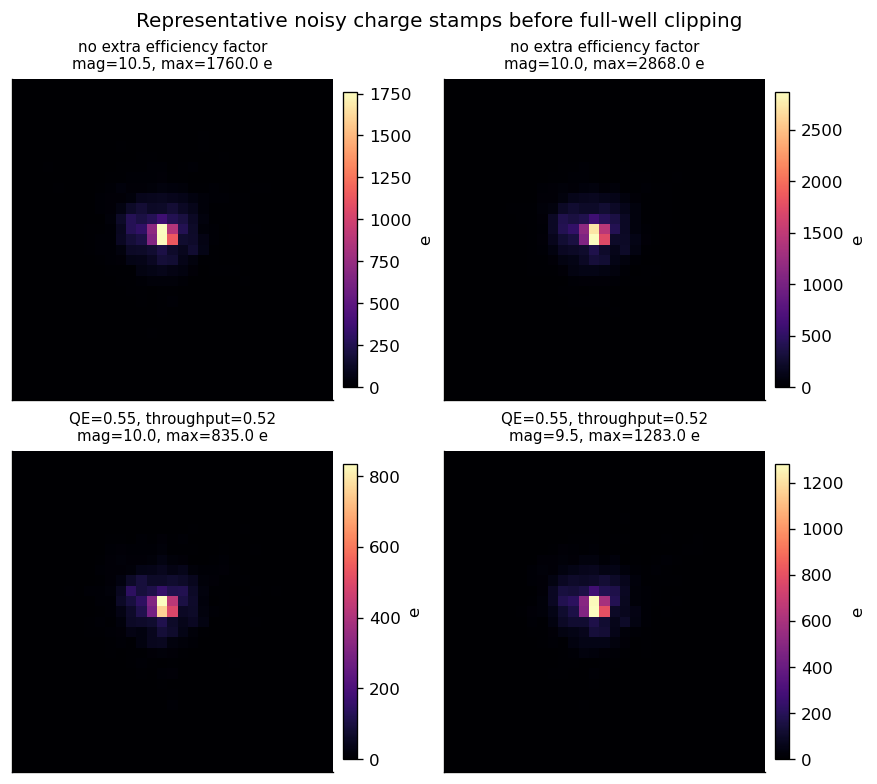

In [9]:
stamp_specs = [
    ('baseline', 10.5, 'charge_before_clip_e'),
    ('baseline', 10.0, 'charge_before_clip_e'),
    ('efficiency', 10.0, 'charge_before_clip_e'),
    ('efficiency', 9.5, 'charge_before_clip_e'),
]
fig, axes = plt.subplots(2, 2, figsize=(7.2, 6.2), constrained_layout=True)
for ax, (case_key, mag, product) in zip(axes.ravel(), stamp_specs):
    key = f"mag_{mag:.1f}_{product}"
    stamp = cases[case_key]['stamps'][key]
    image = ax.imshow(stamp, origin='lower', cmap='magma')
    ax.set_title(f"{cases[case_key]['label']}\nmag={mag:.1f}, max={np.nanmax(stamp):.1f} e", fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.03, label='e')
fig.suptitle('Representative noisy charge stamps before full-well clipping', y=1.03)
fig.savefig(ASSET_DIR / 'microlens_representative_stamps.png', bbox_inches='tight')
plt.show()

In [10]:
rerun_commands = [
    [
        str(PYTHON), str(SCRIPT_PATH),
        '--instrument', 'microlens',
        '--config-xlsx', str(CONFIG_XLSX),
        '--output-dir', str(BASE_DIR),
        '--n-realizations', '500',
        '--seed', str(base_meta['seed']),
        '--device', 'cpu',
    ],
    [
        str(PYTHON), str(SCRIPT_PATH),
        '--instrument', 'microlens',
        '--config-xlsx', str(CONFIG_XLSX),
        '--output-dir', str(EFF_DIR),
        '--n-realizations', '500',
        '--seed', str(base_meta['seed']),
        '--device', 'cpu',
        '--quantum-efficiency', '0.55',
        '--optical-throughput', '0.52',
    ],
]
for command in rerun_commands:
    print(' '.join(command))

/home/liyang/anaconda3/envs/py311/bin/python /home/liyang/ET7/ET-fsgsim/scripts/guide_stamp_saturation_sweep.py --instrument microlens --config-xlsx /home/liyang/ET7/Photsim7-data/et_inputs_microlens_guider.xlsx --output-dir /home/liyang/ET7/Results/FSG_guide_sims/microlens_single_star_saturation_sweep --n-realizations 500 --seed 20260522 --device cpu
/home/liyang/anaconda3/envs/py311/bin/python /home/liyang/ET7/ET-fsgsim/scripts/guide_stamp_saturation_sweep.py --instrument microlens --config-xlsx /home/liyang/ET7/Photsim7-data/et_inputs_microlens_guider.xlsx --output-dir /home/liyang/ET7/Results/FSG_guide_sims/microlens_single_star_saturation_sweep_qe0p55_throughput0p52 --n-realizations 500 --seed 20260522 --device cpu --quantum-efficiency 0.55 --optical-throughput 0.52


## 结论

在 `31 x 31` stamp、PSF 居中、`Subpixels Per Pixel Dim = 1`、曝光 `0.25 s`、满阱 `1800 e` 的条件下：

- 不乘额外效率因子时，`0.5 mag` 粗网格测试给出首次饱和星等为 `mag = 10.5`，全部 realization 饱和从 `mag = 10.0` 开始；进一步做 `0.1 mag` 细步长扫描后，连续阈值约为 `10.481 mag`，`mag = 10.5` 开始出现饱和，而 `mag >= 10.6` 时不再出现饱和。
- 单星和天光背景同时乘 `QE = 0.55`、`throughput = 0.52` 后，`0.5 mag` 粗网格测试给出首次和全部饱和都出现在 `mag = 9.0`；进一步做 `0.1 mag` 细步长扫描后，连续阈值约为 `9.122 mag`，`mag = 9.2` 开始出现饱和，而 `mag >= 9.3` 时不再出现饱和。
- 这里的饱和判据是在读出噪声、gain、bias 和 ADC 之前，对每个像素的 `charge_before_clip_e >= 1800 e` 进行判断；因此结论对应物理满阱饱和，而不是 ADC DN 是否达到 4095。

因此，如果报告中需要给出更精细的表述，可以写作：微引力导星仪在本仿真设置下的连续满阱饱和边界约为 `10.48` 等；若同时乘 `QE=0.55` 与 `throughput=0.52`，连续边界约移动到 `9.12` 等。

/home/liyang/anaconda3/envs/py311/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026-05-24 15:12:01,467	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


,case,continuous_threshold_mag,first_any_fine_mag,first_all_fine_mag,darkest_no_saturation_mag
0,no extra efficiency factor,10.481,10.5,10.4,10.6
1,"QE=0.55, throughput=0.52",9.122,9.2,9.0,9.3


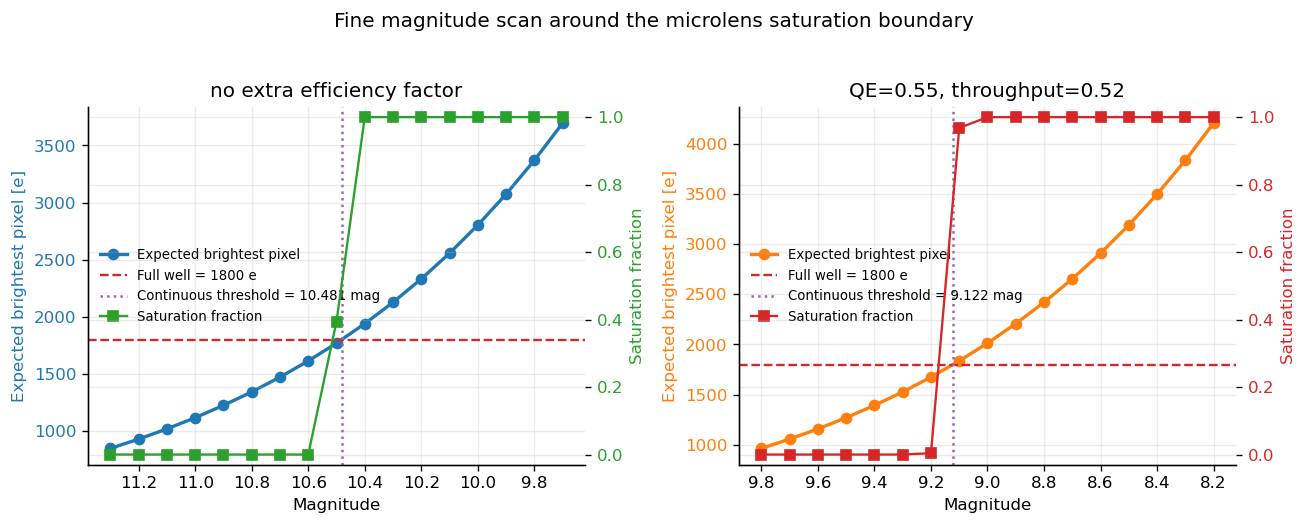

no extra efficiency factor: continuous threshold = 10.481 mag
  first magnitude with any saturation: 10.5 mag
  no saturation for magnitudes >= 10.6 mag within this fine scan
  all realizations saturated starting at 10.4 mag
QE=0.55, throughput=0.52: continuous threshold = 9.122 mag
  first magnitude with any saturation: 9.2 mag
  no saturation for magnitudes >= 9.3 mag within this fine scan
  all realizations saturated starting at 9.0 mag


In [11]:
from pathlib import Path
import importlib.util
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

REPO_DIR = Path('/home/liyang/ET7/ET-fsgsim')
SCRIPT_PATH = REPO_DIR / 'scripts' / 'guide_stamp_saturation_sweep.py'
CONFIG_XLSX = Path('/home/liyang/ET7/Photsim7-data/et_inputs_microlens_guider.xlsx')
BASE_DIR = Path('/home/liyang/ET7/Results/FSG_guide_sims/microlens_single_star_saturation_sweep')
EFF_DIR = Path('/home/liyang/ET7/Results/FSG_guide_sims/microlens_single_star_saturation_sweep_qe0p55_throughput0p52')
ASSET_DIR = Path('/home/liyang/ET7/ET-fsgsim/notebooks/microlens_guide_star_saturation_report_files')
ASSET_DIR.mkdir(parents=True, exist_ok=True)


def load_case_for_fine_scan(label, result_dir):
    result_dir = Path(result_dir)
    summary = pd.read_csv(result_dir / 'saturation_summary.csv')
    for column in ['mag', 'expected_peak_star_e', 'saturation_fraction']:
        summary[column] = pd.to_numeric(summary[column])
    with (result_dir / 'saturation_metadata.json').open('r', encoding='utf-8') as handle:
        metadata = json.load(handle)
    return {'label': label, 'dir': result_dir, 'summary': summary, 'metadata': metadata}


def load_sweep_module(script_path):
    spec = importlib.util.spec_from_file_location('guide_stamp_saturation_sweep_microlens', script_path)
    module = importlib.util.module_from_spec(spec)
    assert spec is not None and spec.loader is not None
    sys.modules[spec.name] = module
    spec.loader.exec_module(module)
    return module


sweep = load_sweep_module(SCRIPT_PATH)
scan_cases = {
    'baseline': load_case_for_fine_scan('no extra efficiency factor', BASE_DIR),
    'efficiency': load_case_for_fine_scan('QE=0.55, throughput=0.52', EFF_DIR),
}


def build_microlens_config(exposure_s):
    return sweep.build_sweep_config(
        type('Args', (), {
            'instrument': 'microlens',
            'output_dir': None,
            'config_xlsx': str(CONFIG_XLSX),
            'focal_length_mm': sweep.MICROLENS_FOCAL_LENGTH_MM,
            'exposure_s': float(exposure_s),
        })()
    )


def run_fine_scan(case_key, case_payload, mag_step=0.1):
    metadata = case_payload['metadata']
    first_any = float(metadata['first_mag_with_any_saturated_realization'])
    fine_mags = np.round(np.arange(first_any + 0.8, first_any - 0.8 - 1e-9, -mag_step), 1)
    config_values = build_microlens_config(metadata['exposure_s'])
    psf_manager = sweep.make_psf_model_manager(config_values, 'cpu', 32)
    photon_efficiency = float(metadata['photon_efficiency'])
    background_counts_e = float(metadata['background_counts_e_per_pix'])
    scattered_counts_e = float(metadata['scattered_counts_e_per_pix'])
    dark_counts_e = float(metadata['dark_counts_e_per_pix'])
    n_realizations = int(metadata['n_realizations_per_mag'])

    rows = []
    for index, mag in enumerate(fine_mags):
        expected_star_e = sweep.render_expected_star(
            config_values,
            psf_manager,
            float(mag),
            'cpu',
            32,
            photon_efficiency=photon_efficiency,
        )
        sim = sweep.simulate_realizations(
            config_values=config_values,
            expected_star_e=expected_star_e,
            rng=np.random.default_rng(int(metadata['seed']) + 1000 * (1 if case_key == 'baseline' else 2) + index),
            n_realizations=n_realizations,
            background_counts_e=background_counts_e,
            scattered_counts_e=scattered_counts_e,
            dark_counts_e=dark_counts_e,
        )
        max_charge_e = sim['charge_before_clip_e'].reshape(n_realizations, -1).max(axis=1)
        rows.append({
            'case': case_payload['label'],
            'mag': float(mag),
            'expected_peak_star_e': float(np.max(expected_star_e)),
            'expected_total_star_e': float(np.sum(expected_star_e)),
            'saturated_frames': int(np.count_nonzero(sim['saturated_pixels_per_frame'] > 0)),
            'saturation_fraction': float(np.mean(sim['saturated_pixels_per_frame'] > 0)),
            'max_charge_e_p95': float(np.percentile(max_charge_e, 95)),
        })

    fine_df = pd.DataFrame(rows).sort_values('mag', ascending=False).reset_index(drop=True)
    full_well = float(metadata['full_well_electrons'])
    interp_df = fine_df.sort_values('expected_peak_star_e')
    continuous_threshold_mag = float(np.interp(full_well, interp_df['expected_peak_star_e'], interp_df['mag']))
    sat_mask = fine_df['saturation_fraction'] > 0.0
    first_any_fine = float(fine_df.loc[sat_mask, 'mag'].iloc[0]) if sat_mask.any() else None
    no_sat_df = fine_df.loc[~sat_mask]
    darkest_no_sat = float(no_sat_df['mag'].iloc[-1]) if not no_sat_df.empty else None
    always_sat_df = fine_df.loc[fine_df['saturation_fraction'] >= 1.0]
    first_all_fine = float(always_sat_df['mag'].iloc[0]) if not always_sat_df.empty else None
    return fine_df, {
        'case': case_payload['label'],
        'continuous_threshold_mag': continuous_threshold_mag,
        'first_any_fine_mag': first_any_fine,
        'first_all_fine_mag': first_all_fine,
        'darkest_no_saturation_mag': darkest_no_sat,
    }


fine_tables = []
threshold_rows = []
for case_key, case_payload in scan_cases.items():
    fine_df, metrics = run_fine_scan(case_key, case_payload, mag_step=0.1)
    fine_tables.append(fine_df)
    threshold_rows.append(metrics)

fine_scan_df = pd.concat(fine_tables, ignore_index=True)
fine_threshold_df = pd.DataFrame(threshold_rows)
fine_scan_df.to_csv(ASSET_DIR / 'microlens_fine_magnitude_saturation_scan.csv', index=False)
fine_threshold_df.to_csv(ASSET_DIR / 'microlens_fine_magnitude_thresholds.csv', index=False)

display(fine_threshold_df.style.format({
    'continuous_threshold_mag': '{:.3f}',
    'first_any_fine_mag': '{:.1f}',
    'first_all_fine_mag': '{:.1f}',
    'darkest_no_saturation_mag': '{:.1f}',
}))

fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.2), sharey=False)
styles = {
    'no extra efficiency factor': {'peak_color': 'tab:blue', 'sat_color': 'tab:green'},
    'QE=0.55, throughput=0.52': {'peak_color': 'tab:orange', 'sat_color': 'tab:red'},
}
full_well = float(scan_cases['baseline']['metadata']['full_well_electrons'])
for ax, (_, threshold_row) in zip(axes, fine_threshold_df.iterrows()):
    case_label = threshold_row['case']
    sub_df = fine_scan_df.loc[fine_scan_df['case'] == case_label].copy()
    style = styles[case_label]
    ax.plot(sub_df['mag'], sub_df['expected_peak_star_e'], color=style['peak_color'], marker='o', lw=2, label='Expected brightest pixel')
    ax.axhline(full_well, color='tab:red', ls='--', lw=1.4, label='Full well = 1800 e')
    ax.axvline(threshold_row['continuous_threshold_mag'], color='tab:purple', ls=':', lw=1.5, label=f"Continuous threshold = {threshold_row['continuous_threshold_mag']:.3f} mag")
    ax.set_xlabel('Magnitude')
    ax.set_ylabel('Expected brightest pixel [e]', color=style['peak_color'])
    ax.tick_params(axis='y', labelcolor=style['peak_color'])
    ax.invert_xaxis()
    ax.set_title(case_label)

    ax2 = ax.twinx()
    ax2.plot(sub_df['mag'], sub_df['saturation_fraction'], color=style['sat_color'], marker='s', lw=1.4, label='Saturation fraction')
    ax2.set_ylabel('Saturation fraction', color=style['sat_color'])
    ax2.tick_params(axis='y', labelcolor=style['sat_color'])
    ax2.set_ylim(-0.03, 1.03)

    handles1, labels1 = ax.get_legend_handles_labels()
    handles2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(handles1 + handles2, labels1 + labels2, frameon=False, loc='center left', fontsize=8)

fig.suptitle('Fine magnitude scan around the microlens saturation boundary', y=1.03)
fig.tight_layout()
fig.savefig(ASSET_DIR / 'microlens_fine_magnitude_peak_e_and_saturation.png', bbox_inches='tight')
plt.show()

for _, row in fine_threshold_df.iterrows():
    print(f"{row['case']}: continuous threshold = {row['continuous_threshold_mag']:.3f} mag")
    if pd.notna(row['first_any_fine_mag']):
        print(f"  first magnitude with any saturation: {row['first_any_fine_mag']:.1f} mag")
    if pd.notna(row['darkest_no_saturation_mag']):
        print(f"  no saturation for magnitudes >= {row['darkest_no_saturation_mag']:.1f} mag within this fine scan")
    if pd.notna(row['first_all_fine_mag']):
        print(f"  all realizations saturated starting at {row['first_all_fine_mag']:.1f} mag")

## 细步长连续星等测试

这里增加一个和凌星报告同风格的细步长连续星等扫描。对微引力导星仪分别在 baseline 情况和 `QE=0.55, throughput=0.52` 分支下，采用 `0.1 mag` 步长扫描饱和边界附近的星等，并输出：

- 期望最亮像素电子数 `expected_peak_star_e`
- 500 次噪声 realization 的饱和比例 `saturation_fraction`
- 由 `expected_peak_star_e = 1800 e` 插值得到的连续阈值星等

这样可以直接回答：从多少等开始出现饱和，以及多少等及更暗不再出现饱和。

## 凌星与微引力 PSF 最亮像素占比对比

由于满阱饱和判据是检查最亮像素在加噪声后的电子数是否达到 `1800 e`，因此可以直接比较两套 PSF 的“最亮像素占总 PSF 能量百分比”。如果两者差别很小，那么在 `0.5 mag` 的扫星等网格下得到相同的首次饱和星等是合理的；如果差别较大，则需要进一步判断它是否足以改变饱和阈值的星等档位。

,case,psf_path,field_id,subpix,psf_shape,peak_index,peak_fraction_percent,peak_over_full_total_percent_from_rendered_stamp,peak_over_stamp_total_percent_from_rendered_stamp,stamp_capture_percent,total_e_for_peak_1800,continuous_mag_peak_1800,first_any_saturation_mag_grid,first_all_saturation_mag_grid,mag_10p5_expected_peak_e,mag_10p5_saturation_fraction,peak_fraction_difference_vs_transit_pctpt,continuous_mag_shift_vs_transit
0,凌星导星,/home/liyang/ET7/Photsim7-data/psf/et/241006/D280mm-focus-guide6p5um/sim_psf_images.pkl,7,1,25 x 25,"(12, 10)",9.470645,9.470644,9.470645,99.999996,19006.10,10.410925,10.0,10.0,1658.222,0.000,0.000000,0.000000
1,微引力导星,/home/liyang/ET7/Photsim7-data/psf/et/microlens/RebinnedPSF_LE_BEST_GD1_Field1_multiband_Defocus0/sim_psf_images.pkl,0,1,157 x 157,"(78, 77)",10.099414,10.099419,10.507720,96.114284,17822.82,10.480717,10.5,10.0,1768.314,0.390,0.628768,0.069791


/tmp/ipykernel_2656020/3400625693.py:142: UserWarning: Glyph 20940 (\N{CJK UNIFIED IDEOGRAPH-51CC}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_2656020/3400625693.py:142: UserWarning: Glyph 26143 (\N{CJK UNIFIED IDEOGRAPH-661F}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_2656020/3400625693.py:142: UserWarning: Glyph 23548 (\N{CJK UNIFIED IDEOGRAPH-5BFC}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_2656020/3400625693.py:142: UserWarning: Glyph 24494 (\N{CJK UNIFIED IDEOGRAPH-5FAE}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_2656020/3400625693.py:142: UserWarning: Glyph 24341 (\N{CJK UNIFIED IDEOGRAPH-5F15}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_2656020/3400625693.py:142: UserWarning: Glyph 21147 (\N{CJK UNIFIED IDEOGRAPH-529B}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_2656020/3400625693.py:143: UserWarning: Glyph 20940 (\N

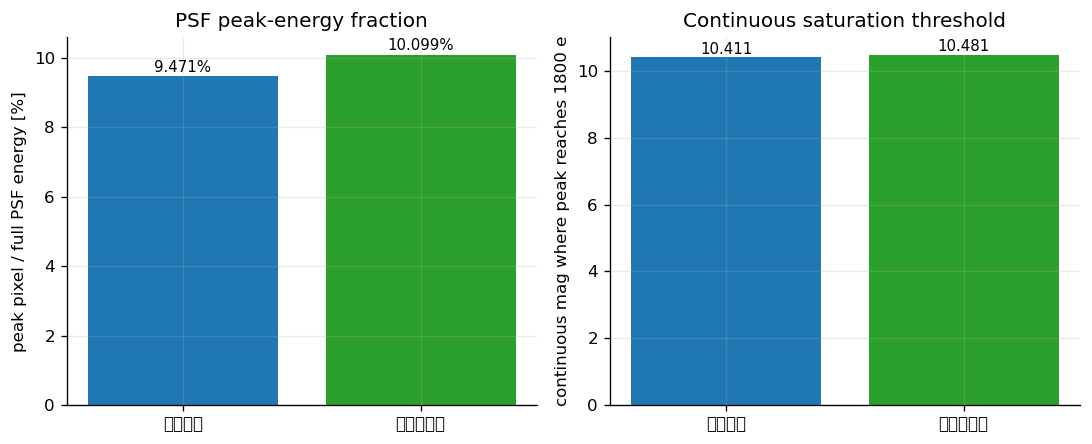

微引力相对凌星的峰值占比相对增幅: 6.6391%
由峰值占比差异推导的连续饱和阈值星等差: 0.069791 mag


In [12]:
from pathlib import Path
import math
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

asset_dir = Path('/home/liyang/ET7/ET-fsgsim/notebooks/microlens_guide_star_saturation_report_files')
asset_dir.mkdir(parents=True, exist_ok=True)

full_well_e = 1800.0
reference_mag = 12.5
reference_total_e = 11100.0 * 0.25

cases = {
    'transit': {
        'label': '凌星导星',
        'psf_path': Path('/home/liyang/ET7/Photsim7-data/psf/et/241006/D280mm-focus-guide6p5um/sim_psf_images.pkl'),
        'field_id': 7,
        'summary_csv': Path('/home/liyang/ET7/Results/FSG_guide_sims/single_star_saturation_sweep/saturation_summary.csv'),
    },
    'microlens': {
        'label': '微引力导星',
        'psf_path': Path('/home/liyang/ET7/Photsim7-data/psf/et/microlens/RebinnedPSF_LE_BEST_GD1_Field1_multiband_Defocus0/sim_psf_images.pkl'),
        'field_id': 0,
        'summary_csv': Path('/home/liyang/ET7/Results/FSG_guide_sims/microlens_single_star_saturation_sweep/saturation_summary.csv'),
    },
}


def load_peak_fraction(psf_path, field_id, subpix=1):
    with psf_path.open('rb') as handle:
        bundle = pickle.load(handle)
    image = np.asarray(bundle['images'][field_id][subpix])
    psf = image[2] if image.ndim == 3 and image.shape[0] >= 3 else image
    total = float(np.nansum(psf))
    peak = float(np.nanmax(psf))
    return {
        'peak_fraction': peak / total,
        'peak_fraction_percent': peak / total * 100.0,
        'peak_pixel_value': peak,
        'total_psf_energy': total,
        'peak_index': np.unravel_index(np.nanargmax(psf), psf.shape),
        'shape': psf.shape,
    }


def load_summary_metrics(summary_csv):
    summary = pd.read_csv(summary_csv)
    total_col = None
    for candidate in [
        'base_photon_count_e_0p25s',
        'base_photon_count_e_per_exposure',
        'photon_count_e_0p25s',
        'photon_count_e_per_exposure',
    ]:
        if candidate in summary.columns:
            total_col = candidate
            break
    if total_col is None:
        raise KeyError(f'Cannot identify total-electron column in {summary_csv}')

    numeric_cols = ['mag', total_col, 'expected_peak_star_e', 'expected_total_star_e', 'saturation_fraction']
    for column in numeric_cols:
        summary[column] = pd.to_numeric(summary[column])

    row14 = summary.loc[np.isclose(summary['mag'], 14.0)].iloc[0]
    return {
        'row14_total_col': total_col,
        'peak_over_full_percent': float(row14['expected_peak_star_e'] / row14[total_col] * 100.0),
        'peak_over_stamp_percent': float(row14['expected_peak_star_e'] / row14['expected_total_star_e'] * 100.0),
        'stamp_capture_percent': float(row14['expected_total_star_e'] / row14[total_col] * 100.0),
        'first_any_mag': float(summary.loc[summary['saturation_fraction'] > 0.0, 'mag'].iloc[0]),
        'first_all_mag': float(summary.loc[summary['saturation_fraction'] >= 1.0, 'mag'].iloc[0]),
        'mag10p5_sat_fraction': float(summary.loc[np.isclose(summary['mag'], 10.5), 'saturation_fraction'].iloc[0]),
        'mag10p5_peak_e': float(summary.loc[np.isclose(summary['mag'], 10.5), 'expected_peak_star_e'].iloc[0]),
    }


rows = []
for key, cfg in cases.items():
    psf_metrics = load_peak_fraction(cfg['psf_path'], cfg['field_id'], subpix=1)
    summary_metrics = load_summary_metrics(cfg['summary_csv'])
    total_needed = full_well_e / psf_metrics['peak_fraction']
    continuous_mag = reference_mag - 2.5 * math.log10(total_needed / reference_total_e)
    rows.append({
        'case': cfg['label'],
        'psf_path': str(cfg['psf_path']),
        'field_id': cfg['field_id'],
        'subpix': 1,
        'psf_shape': f"{psf_metrics['shape'][0]} x {psf_metrics['shape'][1]}",
        'peak_index': str(psf_metrics['peak_index']),
        'peak_fraction_percent': psf_metrics['peak_fraction_percent'],
        'peak_over_full_total_percent_from_rendered_stamp': summary_metrics['peak_over_full_percent'],
        'peak_over_stamp_total_percent_from_rendered_stamp': summary_metrics['peak_over_stamp_percent'],
        'stamp_capture_percent': summary_metrics['stamp_capture_percent'],
        'total_e_for_peak_1800': total_needed,
        'continuous_mag_peak_1800': continuous_mag,
        'first_any_saturation_mag_grid': summary_metrics['first_any_mag'],
        'first_all_saturation_mag_grid': summary_metrics['first_all_mag'],
        'mag_10p5_expected_peak_e': summary_metrics['mag10p5_peak_e'],
        'mag_10p5_saturation_fraction': summary_metrics['mag10p5_sat_fraction'],
    })

comparison_df = pd.DataFrame(rows)
transit_frac = float(comparison_df.loc[comparison_df['case'] == '凌星导星', 'peak_fraction_percent'].iloc[0])
microlens_frac = float(comparison_df.loc[comparison_df['case'] == '微引力导星', 'peak_fraction_percent'].iloc[0])
comparison_df['peak_fraction_difference_vs_transit_pctpt'] = comparison_df['peak_fraction_percent'] - transit_frac
comparison_df['continuous_mag_shift_vs_transit'] = comparison_df['continuous_mag_peak_1800'] - float(comparison_df.loc[comparison_df['case'] == '凌星导星', 'continuous_mag_peak_1800'].iloc[0])
comparison_df.to_csv(asset_dir / 'transit_vs_microlens_psf_peak_fraction_comparison.csv', index=False)

display(comparison_df.style.format({
    'peak_fraction_percent': '{:.6f}',
    'peak_over_full_total_percent_from_rendered_stamp': '{:.6f}',
    'peak_over_stamp_total_percent_from_rendered_stamp': '{:.6f}',
    'stamp_capture_percent': '{:.6f}',
    'total_e_for_peak_1800': '{:.2f}',
    'continuous_mag_peak_1800': '{:.6f}',
    'first_any_saturation_mag_grid': '{:.1f}',
    'first_all_saturation_mag_grid': '{:.1f}',
    'mag_10p5_expected_peak_e': '{:.3f}',
    'mag_10p5_saturation_fraction': '{:.3f}',
    'peak_fraction_difference_vs_transit_pctpt': '{:.6f}',
    'continuous_mag_shift_vs_transit': '{:.6f}',
}))

fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.8))
axes[0].bar(comparison_df['case'], comparison_df['peak_fraction_percent'], color=['tab:blue', 'tab:green'])
axes[0].set_ylabel('peak pixel / full PSF energy [%]')
axes[0].set_title('PSF peak-energy fraction')
for idx, value in enumerate(comparison_df['peak_fraction_percent']):
    axes[0].text(idx, value + 0.05, f'{value:.3f}%', ha='center', va='bottom', fontsize=9)

axes[1].bar(comparison_df['case'], comparison_df['continuous_mag_peak_1800'], color=['tab:blue', 'tab:green'])
axes[1].set_ylabel('continuous mag where peak reaches 1800 e')
axes[1].set_title('Continuous saturation threshold')
for idx, value in enumerate(comparison_df['continuous_mag_peak_1800']):
    axes[1].text(idx, value + 0.01, f'{value:.3f}', ha='center', va='bottom', fontsize=9)

fig.tight_layout()
fig.savefig(asset_dir / 'transit_vs_microlens_psf_peak_fraction.png', bbox_inches='tight')
plt.show()

print(f'微引力相对凌星的峰值占比相对增幅: {(microlens_frac / transit_frac - 1.0) * 100.0:.4f}%')
print(f'由峰值占比差异推导的连续饱和阈值星等差: {comparison_df.loc[comparison_df["case"] == "微引力导星", "continuous_mag_shift_vs_transit"].iloc[0]:.6f} mag')

从这个比较可以看出：

- 凌星导星 PSF 的最亮像素占完整 PSF 总能量约 `9.4706%`。
- 微引力导星 PSF 的最亮像素占完整 PSF 总能量约 `10.0994%`。
- 微引力比凌星高 `0.6288` 个百分点，折合相对增幅约 `6.64%`。
- 但把这个差异换算成“最亮像素刚好达到 `1800 e` 的连续阈值星等”后，二者只相差约 `0.07 mag`，明显小于当前扫星等的 `0.5 mag` 网格步长。

因此，这个差异**会影响边界星等的饱和概率**，例如在 `mag=10.5` 处微引力明显更接近饱和；但它**不足以改变**当前 `0.5 mag` 网格下“首次出现饱和”和“全部饱和”所在的星等档位判断。